In [2]:
# 1. Imports
import pandas as pd
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import joblib

In [3]:
# 2. Carregar dados do banco SQLite
conn = sqlite3.connect("data/PROCESSED/titanic.db")
df = pd.read_sql_query("SELECT * FROM titanic", conn)
conn.close()

In [4]:
# 3. Análise exploratória
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,None,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,None,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,None,S


In [27]:
df.groupby("Survived").count()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Survived,,,,,,,,,,,
0,549,549,549,549,424,549,549,549,549,68,549
1,342,342,342,342,290,342,342,342,342,136,340


In [6]:
# 4. Pré-processamento
df_tratado = df.drop(columns=["Name", "Ticket", "Cabin"])  # remove colunas irrelevantes
df_tratado = df_tratado.dropna()  # remove linhas com valores nulos
df_tratado = pd.get_dummies(df_tratado, columns=["Sex", "Embarked"], drop_first=True)

In [7]:
# 5. Separar variáveis
X = df_tratado.drop("Survived", axis=1)
y = df_tratado["Survived"]

# 6. Treinamento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

c:\Users\pedro\OneDrive\1- ESTUDO\2- FIAP\1- POS TECH MACHINE LEARNING\F3\TECHCHALLENGER\MLET_FASE3_TC\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


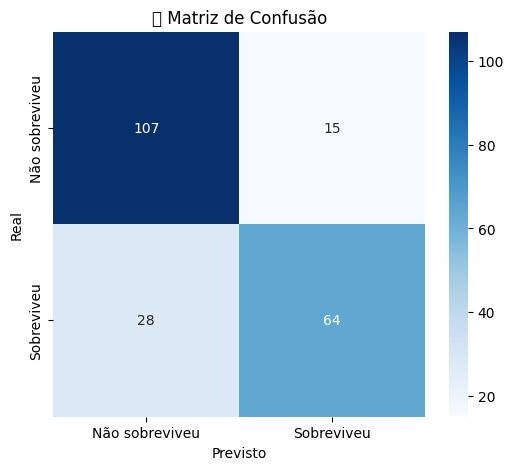

c:\Users\pedro\OneDrive\1- ESTUDO\2- FIAP\1- POS TECH MACHINE LEARNING\F3\TECHCHALLENGER\MLET_FASE3_TC\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


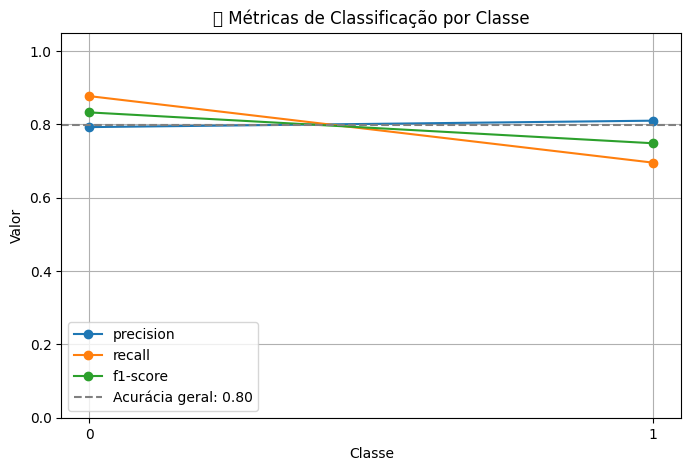

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
# Previsões
y_pred = model.predict(X_test)

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
labels = ['Não sobreviveu', 'Sobreviveu']

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('🔍 Matriz de Confusão')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()

# Relatório de classificação
report = classification_report(y_test, y_pred, output_dict=True)
accuracy = accuracy_score(y_test, y_pred)

# Gráfico de métricas
metrics = ['precision', 'recall', 'f1-score']
classes = ['0', '1']  # 0 = Não sobreviveu, 1 = Sobreviveu

plt.figure(figsize=(8, 5))
for metric in metrics:
    values = [report[cls][metric] for cls in classes]
    plt.plot(classes, values, marker='o', label=metric)

# Adiciona acurácia como linha horizontal
plt.axhline(y=accuracy, color='gray', linestyle='--', label=f'Acurácia geral: {accuracy:.2f}')

plt.title('📈 Métricas de Classificação por Classe')
plt.xlabel('Classe')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# 8. Salvar modelo
joblib.dump(model, "modelo/modelo_final.pkl")

['modelo/modelo_final.pkl']